# Lab 7: Fine-Tune a Small Language Model with LoRA (INSTRUCTOR SOLUTION)

Every TODO is completed and marked `(solution)` in the code. Reflection answer keys are in Part G. The student version is `Lab7_FineTuning_LoRA.ipynb`.
**IST 688 · Building Human-Centered AI Applications · About 40 minutes**

## Goal
In this lab you will fine-tune a small open-weight language model (**Qwen2.5-0.5B-Instruct**) to triage campus IT help-desk tickets. Given a ticket, the model must reply with **only** a JSON object containing a `category` and a `priority`, for example:

```json
{"category": "printing", "priority": "low"}
```

You will clean a flawed training set, measure the model **before** fine-tuning (with a minimal prompt and with a carefully engineered prompt), train **LoRA** adapters, and measure again on 30 held-out tickets. You don't need great results. The goal is to see what fine-tuning changes, what it costs, and when it's worth it compared with prompting.

## Cost and access
- **No API key or payment is needed.** The model downloads from Hugging Face inside Colab.
- You need a free **Google account** to run code in Colab.

## Before you start
1. **Open the notebook in Colab.**
   - If you received this as a `.ipynb` file: go to [colab.research.google.com](https://colab.research.google.com) → **File → Upload notebook**.
   - If you opened a shared link: choose **File → Save a copy in Drive** *before* you start editing, so your work autosaves.
2. **Set the runtime:** **Runtime → Change runtime type**, then:
   - **Runtime type:** make sure it is **Python 3**.
   - **Hardware accelerator:** select **T4 GPU** (an accelerator must be selected).
   - **Runtime version:** leave it on **Latest (recommended)**.
   - Click **Save**.
3. **How to run a cell:** click the **play icon** (▶) on the left of a code cell, or click inside the cell and press **Shift + Enter**. Wait for it to finish (a green check appears) before running the next one.
4. **Run the cells in order, top to bottom.** If anything breaks, use **Runtime → Restart session** and run again from Cell 1.

## Results
Fill this in as you go (double-click this cell to edit it).

**Dataset check (from your TODO 1 code in Cell 3)**
- Raw training rows:
- Test rows:
- The first 5 rows your code printed (paste them between the lines below):
```
paste here
```

**LoRA settings (Cell 8):** r = , lora_alpha = , trainable parameters = %

**Model results:** copy the percentages printed by Cells 6 and 10.

| Condition | Format OK | Category accuracy | Priority accuracy |
|---|---|---|---|
| Before FT · minimal prompt | | | |
| Before FT · detailed prompt | | | |
| After FT · minimal prompt | | | |

---
# Part A · Setup (about 5 min)

### Cell 1 · Prepare the libraries and check the GPU
Run the cell below. It:
- installs **PEFT** only if it's missing;
- checks for the GPU.

**About the libraries:** `torch` (PyTorch) is the deep-learning engine that stores the model's numbers and runs the math on the GPU; `transformers` (Hugging Face) downloads pretrained language models and their tokenizers and runs them; `peft` (Hugging Face) adds parameter-efficient fine-tuning methods such as LoRA.

The first run takes about **30–40 seconds** while Colab loads PyTorch and the GPU libraries. This is normal.

It should print **`GPU available: True`** and a GPU name (for example, *Tesla T4*).

**If it doesn't:**
- **It prints `GPU available: False`:** go to **Runtime → Change runtime type → T4 GPU → Save**, then run Cell 1 again.
- **No GPU can be assigned** (Colab usage limits): continue anyway. The notebook switches to a smaller model on CPU automatically. It's slower, but it works.
- **An error appears after the install line:** use **Runtime → Restart session**, then run Cell 1 again.

In [ ]:
import importlib, importlib.util, subprocess, sys

if importlib.util.find_spec("torchao") is not None:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)
    importlib.invalidate_caches()

# Install PEFT only if it's missing
if importlib.util.find_spec("peft") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "peft"], check=True)

import torch, transformers, peft
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| peft", peft.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | transformers 5.20.2 | peft 0.21.2
GPU available: True
GPU: Tesla T4


### Cell 2 · Load the model
This downloads the model and its tokenizer from Hugging Face (about a minute). Note the parameter count it prints.

In [ ]:
import json, random, re, time
from collections import Counter
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# A smaller fallback model is used automatically if no GPU is available
MODEL_ID = ("Qwen/Qwen2.5-0.5B-Instruct" if DEVICE == "cuda"
            else "HuggingFaceTB/SmolLM2-135M-Instruct")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# float32 because the T4 GPU does not support bfloat16
# (if you get a TypeError about "dtype", change dtype= to torch_dtype=)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32).to(DEVICE)
print(f"Loaded {MODEL_ID}: {model.num_parameters() / 1e6:.0f}M parameters on {DEVICE}")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-0.5B-Instruct: 494M parameters on cuda


---
# Part B · Build and clean the data (about 8 min)

### Cell 3 · Build the dataset
Each row has a `ticket`, a `category`, and a `priority`. The **category** comes from the problem described; the **priority** comes from the urgency phrase (*"my exam starts in an hour"* = high, *"no rush"* = low).

The 30 **test** tickets use problem descriptions and urgency phrases that never appear in training, so a good test score means the model generalized rather than memorized. The raw training data also contains some **deliberate data-quality problems**.

**TODO 1:** at the bottom of the cell, write code that:
1. prints the number of raw training rows and test rows in this format: `Raw training rows: N | Test rows: N`
2. prints the first 5 rows of `raw_train`, one per line.

*Hints:* `len(some_list)` gives a list's length, and `some_list[:5]` gives its first five items.

Run the cell, read the five rows, and record the counts and rows in the **Results** section at the top.

✅ **Checkpoint:** `Raw training rows: 171 | Test rows: 30`, followed by five rows.

> **Instructor note: why each priority has 10 training phrasings.** In the first dry run, each priority was taught with only 4 urgency phrases. Training loss fell to about 0.01, but after fine-tuning the model answered "high" for every test ticket (priority 33%): it had memorized the 4 phrases instead of learning what urgency means, and fell back to a default on unseen wording. Category reached 90% because test problems share obvious vocabulary with training ones. Giving each priority 10 varied phrasings (2 more held out for testing) targets that coverage gap. It's a useful Q&A example: more *diverse* data, not more epochs, is what fixes memorization.

In [ ]:
CATEGORIES = ["account_access", "wifi_network", "software", "hardware", "printing"]
PRIORITIES = ["low", "medium", "high"]

# First 6 problems per category are for training; the last 2 are held out for testing
PROBLEMS = {
    "account_access": [
        "I can't log in to my university account",
        "my password reset link says it has expired",
        "two-factor authentication keeps rejecting my code",
        "I'm locked out of my student email",
        "my account says it has been disabled",
        "the single sign-on page keeps sending me back to the login screen",
        "I never got the verification code for my new account",
        "the system won't accept my new password"],
    "wifi_network": [
        "the campus Wi-Fi keeps disconnecting",
        "my laptop can't find the campus wireless network",
        "the internet in my dorm room is extremely slow",
        "the ethernet port in my office isn't working",
        "I'm connected to Wi-Fi but no websites load",
        "the VPN won't connect from off campus",
        "my phone won't join the eduroam network",
        "the wireless signal drops whenever I walk into the library"],
    "software": [
        "Microsoft Word crashes every time I open a file",
        "I can't install the statistics software for my class",
        "my license for the design software says it expired",
        "Zoom won't share my screen",
        "the course website gives me an error when I upload homework",
        "Excel freezes when I open large spreadsheets",
        "my laptop says a required software update failed",
        "the coding environment for my class won't launch"],
    "hardware": [
        "my laptop won't turn on",
        "the projector in the classroom has no signal",
        "my monitor keeps flickering",
        "the keyboard on the lab computer is missing keys",
        "my laptop battery dies after twenty minutes",
        "the desktop computer makes a loud clicking noise",
        "the screen on my tablet is cracked and unresponsive",
        "the docking station doesn't charge my laptop anymore"],
    "printing": [
        "the library printer says it's out of toner",
        "my print job is stuck in the queue",
        "I can't add the campus printer to my laptop",
        "the printer in the lab keeps jamming",
        "my printing balance didn't update after I added money",
        "everything I print comes out blank",
        "the color printer only prints in black and white",
        "I sent a document to print but nothing came out"],
}
# Priority comes from the urgency phrase. First 10 phrases per priority are for training;
# the last 2 are held out for testing
CONTEXTS = {
    "high": ["and my exam starts in an hour.",
             "and the whole class of 40 students is affected.",
             "and my thesis is due tonight.",
             "and I'm presenting to the department in 20 minutes.",
             "so I can't submit my final project, which is due at noon.",
             "and the entire team is stuck until it's fixed.",
             "this is urgent because my midterm begins in 15 minutes.",
             "and our grant application must be submitted by 5 pm today.",
             "and I need it working right now for a client meeting.",
             "please help ASAP, my defense starts this afternoon.",
             "and our payroll deadline is in two hours.",
             "and it's holding up a whole lecture hall right now."],
    "medium": ["and it's slowing down my work today.",
               "and I have a workaround, but it's annoying.",
               "and it started this morning.",
               "and it happens a few times a day.",
               "so I'd appreciate a fix in the next day or two.",
               "it's not stopping me completely, but it's frustrating.",
               "and I can still work, just more slowly.",
               "could someone look at it before the end of the week?",
               "it's been on and off since yesterday.",
               "and it's making some tasks take twice as long.",
               "and I'd like it fixed sometime this week.",
               "and it's an inconvenience, though I can get by for now."],
    "low": ["but there's no rush.",
            "just wondering if this is normal.",
            "whenever someone has time is fine.",
            "it's not urgent at all.",
            "and it can definitely wait until next month.",
            "no hurry, I'm just curious.",
            "and I don't need it anytime soon.",
            "feel free to get to it when things are quiet.",
            "it's a minor thing and doesn't affect my work.",
            "and I'm only asking so I know for next semester.",
            "mostly asking for future reference.",
            "so take your time with this one."],
}
OPENERS = ["Hi,", "Hello,", "Hi IT team,", "Good morning,", ""]
CLOSERS = ["Thanks.", "Thank you!", "", "- Sam", "Any help is appreciated."]

def make_ticket(problem, context, rng):
    opener, closer = rng.choice(OPENERS), rng.choice(CLOSERS)
    body = f"{opener} {problem}" if opener else problem[0].upper() + problem[1:]
    return f"{body}, {context} {closer}".strip()

def build_datasets(seed=SEED, n_train=150):
    rng = random.Random(seed)
    train, seen = [], set()

    def fresh(cat, pri, split, ctx=None):
        probs = PROBLEMS[cat][:6] if split == "train" else PROBLEMS[cat][6:]
        ctxs = CONTEXTS[pri][:10] if split == "train" else CONTEXTS[pri][10:]
        while True:
            t = make_ticket(rng.choice(probs), ctx or rng.choice(ctxs), rng)
            if t not in seen:
                seen.add(t)
                return t

    # Balanced: every training phrase is used exactly 5 times, once with each category
    for i in range(n_train):
        cat, pri = CATEGORIES[i % 5], PRIORITIES[(i // 5) % 3]
        ctx = CONTEXTS[pri][(i // 15) % 10]
        train.append({"ticket": fresh(cat, pri, "train", ctx), "category": cat, "priority": pri})

    test = [{"ticket": make_ticket(p, CONTEXTS[pri][10 + j], rng), "category": cat, "priority": pri}
            for cat in CATEGORIES for j, p in enumerate(PROBLEMS[cat][6:])
            for pri in PRIORITIES]

    # Deliberate data-quality problems for Part B
    raw = list(train)
    raw += [dict(rng.choice(train)) for _ in range(8)]                   # duplicates
    raw += [{"ticket": t, "category": "printing", "priority": "low"}
            for t in ["", "   ", "", "\n"]]                               # empty tickets
    bad_labels = [("Printing", "low"), ("wifi", "high"), ("network_issue", "medium"),
                  ("software", "urgent"), ("hardware", "HIGH"), ("printing", "")]
    for bad_cat, bad_pri in bad_labels:
        cat = rng.choice(CATEGORIES)
        raw.append({"ticket": fresh(cat, "medium", "train"),
                    "category": bad_cat, "priority": bad_pri})          # invalid labels
    for cat, wrong in [("printing", "wifi_network"), ("hardware", "software"),
                       ("account_access", "printing")]:
        raw.append({"ticket": fresh(cat, "low", "train"),
                    "category": wrong, "priority": "low"})               # mislabeled
    rng.shuffle(raw)
    return raw, test

raw_train, test_rows = build_datasets()

# TODO 1 (solution)
print(f"Raw training rows: {len(raw_train)} | Test rows: {len(test_rows)}")
for row in raw_train[:5]:
    print(row)

Raw training rows: 171 | Test rows: 30
{'ticket': "Hi, my password reset link says it has expired, and it's making some tasks take twice as long.", 'category': 'account_access', 'priority': 'medium'}
{'ticket': "Hello, I'm connected to Wi-Fi but no websites load, so I can't submit my final project, which is due at noon. Any help is appreciated.", 'category': 'wifi_network', 'priority': 'high'}
{'ticket': 'Hi IT team, two-factor authentication keeps rejecting my code, and the whole class of 40 students is affected. Thank you!', 'category': 'account_access', 'priority': 'high'}
{'ticket': "I can't install the statistics software for my class, and our grant application must be submitted by 5 pm today.", 'category': 'software', 'priority': 'high'}
{'ticket': "My laptop won't turn on, this is urgent because my midterm begins in 15 minutes. Thanks.", 'category': 'hardware', 'priority': 'high'}


### Cell 4 · Clean the training data (TODO 2–4)
**Write your own function** named `clean_dataset` at the top of the cell below. It takes a list of rows (each row is a dictionary with the keys `ticket`, `category`, and `priority`) and **returns a new list** containing only the usable rows. Your function must:
1. **TODO 2:** skip rows whose ticket is empty or only whitespace,
2. **TODO 3:** skip rows whose category is not in `CATEGORIES` or whose priority is not in `PRIORITIES`,
3. **TODO 4:** skip duplicate tickets, keeping only the first occurrence.

*Hints:* `.strip()` removes surrounding whitespace; `x in some_list` checks membership; a `set` is a good way to remember tickets you've already kept; `continue` skips to the next loop iteration.

The lines below your function are provided: they run your function on `raw_train` and print the result. Don't change them.

✅ **Checkpoint:** the cell should print **171 raw rows → 153 clean rows**, with roughly balanced counts.

In [ ]:
# TODO 2-4 (solution)
def clean_dataset(rows):
    cleaned, seen = [], set()
    for row in rows:
        ticket = row["ticket"].strip()
        if not ticket:                                   # TODO 2: empty ticket
            continue
        if row["category"] not in CATEGORIES or row["priority"] not in PRIORITIES:
            continue                                     # TODO 3: invalid label
        if ticket in seen:                               # TODO 4: duplicate
            continue
        seen.add(ticket)
        cleaned.append(row)
    return cleaned



# ---- provided: do not change ----
assert "clean_dataset" in globals(), "TODO 2-4: write the clean_dataset(rows) function above"
train_rows = clean_dataset(raw_train)
print(f"{len(raw_train)} raw rows -> {len(train_rows)} clean rows (expected: 153)")
print("Category counts:", Counter(r["category"] for r in train_rows))
print("Priority counts:", Counter(r["priority"] for r in train_rows))

171 raw rows -> 153 clean rows (expected: 153)
Category counts: Counter({'wifi_network': 31, 'software': 31, 'printing': 31, 'account_access': 30, 'hardware': 30})
Priority counts: Counter({'low': 53, 'medium': 50, 'high': 50})


---
# Part C · Baselines (about 6 min)

### Cell 5 · Prompts and helper functions (TODO 5–6)
The model will be tested with two prompts:
- **`SYSTEM_PROMPT`** (provided): a minimal one-line instruction.
- **`DETAILED_PROMPT`** (you create it): an engineered prompt with the allowed labels, rules, and an example. This is your Week 3 prompt engineering.

**TODO 5:** where marked in the cell below, create a variable named `DETAILED_PROMPT` that combines `SYSTEM_PROMPT` with the following text (it is one continuous piece of text):

```text
Read the ticket and reply with ONLY a JSON object with two keys: "category" (one of: account_access, wifi_network, software, hardware, printing) and "priority" (one of: low, medium, high). Use high when a deadline, exam, class, or many people are affected right now; medium when work is impaired but can wait a little; low when the person says there is no rush. Example: {"category": "printing", "priority": "low"}
```

*Hints:* `+` joins strings; leave a space between the two parts; the text contains double quotes (`"`), so think about which quotes you wrap it in.

**TODO 6:** write a function named `build_messages(ticket, system_prompt)` that packages a ticket into the chat format the model expects: a **list of messages**, where each message is a dictionary with a `"role"` and a `"content"`. This is the same message format you used with the OpenAI API earlier in the course. Follow the **pseudocode** in the cell where TODO 6 is marked.

The rest of the cell is provided. `evaluate()` runs the model on every test ticket and reports three scores: **format OK** (valid JSON with allowed values), **category accuracy**, and **priority accuracy**.

✅ **Checkpoint:** the cell prints two things:
1. your `DETAILED_PROMPT` as one line, starting with *"You are a campus IT help desk triage assistant. Read the ticket…"* and ending with the example JSON;
2. the result of calling your `build_messages` on an example ticket: a list of two dictionaries, the system message first and then the user message.

In [ ]:
SYSTEM_PROMPT = "You are a campus IT help desk triage assistant."

# TODO 5 (solution)
DETAILED_PROMPT = (
    SYSTEM_PROMPT + " Read the ticket and reply with ONLY a JSON object with two keys: "
    '"category" (one of: account_access, wifi_network, software, hardware, printing) and '
    '"priority" (one of: low, medium, high). Use high when a deadline, exam, class, or many '
    "people are affected right now; medium when work is impaired but can wait a little; "
    "low when the person says there is no rush. "
    'Example: {"category": "printing", "priority": "low"}')



# TODO 6 (solution)
def build_messages(ticket, system_prompt):
    return [{"role": "system", "content": system_prompt},
            {"role": "user", "content": ticket}]



def generate(model, ticket, system_prompt, max_new_tokens=40):
    prompt = tokenizer.apply_chat_template(build_messages(ticket, system_prompt),
                                           tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(DEVICE)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             repetition_penalty=1.0, pad_token_id=tokenizer.pad_token_id)
    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

def parse_prediction(text):
    match = re.search(r"\{.*?\}", text, re.DOTALL)
    if not match:
        return {}
    try:
        obj = json.loads(match.group(0))
    except json.JSONDecodeError:
        return {}
    return obj if isinstance(obj, dict) else {}

def preview(text, width=160):
    # One-line version of a reply for display, trimmed at a whole word (never mid-word)
    text = " ".join(text.split())
    if not text:
        return "(empty reply)"
    if len(text) <= width and text.endswith(("}", ".", "!", "?", '"')):
        return text
    return text[:width + 1].rsplit(" ", 1)[0] + " …"

def evaluate(model, rows, system_prompt, label, show=3):
    model.eval()
    fmt = cat = pri = 0
    for i, row in enumerate(rows):
        reply = generate(model, row["ticket"], system_prompt)
        pred = parse_prediction(reply)
        fmt += pred.get("category") in CATEGORIES and pred.get("priority") in PRIORITIES
        cat += pred.get("category") == row["category"]
        pri += pred.get("priority") == row["priority"]
        if i < show:
            print(f"  TICKET: {row['ticket']}\n  REPLY : {preview(reply)}\n")
    n = len(rows)
    res = {"format_ok": fmt / n, "category_acc": cat / n, "priority_acc": pri / n}
    print(f"[{label}] format OK {res['format_ok']:.0%} | category {res['category_acc']:.0%}"
          f" | priority {res['priority_acc']:.0%}")
    return res

# ---- provided: check your work ----
assert "DETAILED_PROMPT" in globals(), "TODO 5: create DETAILED_PROMPT above"
assert "build_messages" in globals(), "TODO 6: write build_messages above"
example = build_messages("My laptop won't turn on.", SYSTEM_PROMPT)
assert isinstance(example, list) and len(example) == 2, "TODO 6: return a list of 2 messages"
print(DETAILED_PROMPT)
print(example)

You are a campus IT help desk triage assistant. Read the ticket and reply with ONLY a JSON object with two keys: "category" (one of: account_access, wifi_network, software, hardware, printing) and "priority" (one of: low, medium, high). Use high when a deadline, exam, class, or many people are affected right now; medium when work is impaired but can wait a little; low when the person says there is no rush. Example: {"category": "printing", "priority": "low"}
[{'role': 'system', 'content': 'You are a campus IT help desk triage assistant.'}, {'role': 'user', 'content': "My laptop won't turn on."}]


### Cell 6 · Measure the model BEFORE fine-tuning
**TODO 7:** create two variables by calling the `evaluate` function from Cell 5. `evaluate` takes four arguments, in this order: the model, the test set, a prompt, and a label for the printout.
1. **`before_minimal`**: call `evaluate` with the arguments `model`, `test_rows`, `SYSTEM_PROMPT`, and the label `"Before FT | minimal prompt"`.
2. **`before_detailed`**: call `evaluate` with the arguments `model`, `test_rows`, `DETAILED_PROMPT`, and the label `"Before FT | detailed prompt"`.

Each call scores the untuned model on all 30 test tickets, prints the first 3 replies and a summary line, and returns the scores (Cell 10 uses them later). Warnings about `temperature` or `top_p` are safe to ignore.

⏱ **This cell takes about 50 seconds to run**, because the model writes 60 replies (30 tickets × 2 prompts). Wait for the green check before moving on.

Copy the two summary lines (format OK, category, priority) into the **Results** section at the top.

In [ ]:
# TODO 7 (solution)
before_minimal = evaluate(model, test_rows, SYSTEM_PROMPT, "Before FT | minimal prompt")
before_detailed = evaluate(model, test_rows, DETAILED_PROMPT, "Before FT | detailed prompt")



# ---- provided: check your work ----
assert "before_minimal" in globals() and "before_detailed" in globals(), \
    "TODO 7: create both before_minimal and before_detailed"

  TICKET: Hello, I never got the verification code for my new account, mostly asking for future reference. - Sam
  REPLY : Hello Sam! I'm sorry to hear that you're having trouble with your new account. Here are a few steps you can take to try and resolve the issue: 1. **Check Your …

  TICKET: Hi IT team, I never got the verification code for my new account, and I'd like it fixed sometime this week.
  REPLY : I'm sorry to hear that you're having trouble with your account. We understand that verification codes can sometimes get lost or forgotten, and we want to make …

  TICKET: Hello, I never got the verification code for my new account, and our payroll deadline is in two hours. Thank you!
  REPLY : I'm sorry to hear that you're having trouble with your account. Can you please provide me with the verification code you received?

[Before FT | minimal prompt] format OK 0% | category 0% | priority 0%
  TICKET: Hello, I never got the verification code for my new account, mostly asking for 

---
# Part D · Prepare training (about 8 min)

### Cell 7 · Tokenize with label masking (TODO 8)
Each training example becomes token IDs: the chat-formatted prompt followed by the JSON answer and an end-of-sequence token, which teaches the model to stop.

**TODO 8:** in the cell below, **modify the line `labels = None`** (it's marked with a comment) so that `labels` is a list with **one entry for every token in `input_ids`**:
- each **prompt** position gets **-100**. PyTorch ignores any position labeled -100 when computing the loss, so the model isn't trained to predict the prompt;
- each **answer** position keeps its **real token ID**, which are the values in `answer_ids`.

In other words, `labels` = a run of `-100`s (one for each prompt token) followed by the answer token IDs.

**Example with made-up numbers** (your real lists are much longer):
```python
prompt_ids = [11, 12, 13]
answer_ids = [21, 22, 99]
input_ids  = [11, 12, 13, 21, 22, 99]
labels     = [-100, -100, -100, 21, 22, 99]
```

*Hints:*
- `[x] * n` makes a list of `n` copies of `x`: `[0] * 3` gives `[0, 0, 0]`
- `+` joins two lists: `[1, 2] + [3]` gives `[1, 2, 3]`
- `len(prompt_ids)` tells you how many prompt tokens there are

✅ **Checkpoint:** the cell prints the number of tokens in the first example and how many count toward the loss. The second number should be **much smaller**, because only the JSON answer and the end token count.

In [ ]:
def tokenize_example(row):
    prompt = tokenizer.apply_chat_template(build_messages(row["ticket"], SYSTEM_PROMPT),
                                           tokenize=False, add_generation_prompt=True)
    answer = json.dumps({"category": row["category"], "priority": row["priority"]})
    prompt_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(answer, add_special_tokens=False)["input_ids"]
    answer_ids = answer_ids + [tokenizer.eos_token_id]
    input_ids = prompt_ids + answer_ids
    labels = [-100] * len(prompt_ids) + answer_ids   # TODO 8 (solution)
    return {"input_ids": input_ids, "labels": labels}

train_features = [tokenize_example(r) for r in train_rows]
ex = train_features[0]
assert ex["labels"] is not None, "TODO 8: build the labels list first"
assert len(ex["labels"]) == len(ex["input_ids"]), "TODO 8: labels must be as long as input_ids"
print("Tokens in first example:", len(ex["input_ids"]),
      "| tokens that count toward the loss:", sum(l != -100 for l in ex["labels"]))

Tokens in first example: 60 | tokens that count toward the loss: 14


### Cell 8 · Add LoRA adapters (TODO 9–10)
LoRA freezes the model's original weights and adds small trainable matrices to selected layers. The `LoraConfig` controls how:
- **`r` (rank):** the inner size of the two small matrices LoRA adds to each targeted layer. It sets how much the adapter can learn: a higher `r` means more trainable parameters and more capacity, but also more memory and a higher risk of overfitting a small dataset.
- **`lora_alpha` (scaling factor):** how strongly the LoRA update is applied. The update is multiplied by `lora_alpha / r`, so a larger `lora_alpha` (for the same `r`) means a stronger update.
- **`target_modules`:** the names of the layers inside the model that receive LoRA adapters. Here they are the attention projections (`q_proj`, `k_proj`, `v_proj`, `o_proj`) and the MLP layers (`gate_proj`, `up_proj`, `down_proj`). These are provided.
- **`lora_dropout`** (provided): randomly drops part of the LoRA input during training, a mild guard against overfitting.

**TODO 9:** on the two lines marked in the cell below, enter your own whole-number values:
- **`r`:** a suggested range is **between 7 and 9**. This is a small, narrow task (two labels in a fixed format) trained on only about 150 examples. A small rank gives the adapter enough capacity to learn it while adding very few parameters, which keeps training fast on the free GPU and limits overfitting. Ranks around this size are a common starting point for narrow tasks.
- **`lora_alpha`:** a suggested range is **between 14 and 18**. A common rule of thumb sets `lora_alpha` to about **twice `r`**, which makes the scaling factor `lora_alpha / r` about 2: a moderate update strength.

**TODO 10:** wrap the model with LoRA, then print how many of its parameters will be trained. Pseudocode:
```text
model = get_peft_model( <the current model>, <your LoRA config> )
call print_trainable_parameters() on the wrapped model   (it takes no arguments)
```

✅ **Checkpoint:** with `r = 8` it prints about **4.4 million trainable parameters out of about 498 million (≈ 0.88%)**. Other `r` values change these numbers slightly. Record your `r`, your `lora_alpha`, and the **percentage** in the **Results** section.

⚠️ **Run this cell only once.** Running it again wraps LoRA twice. If that happens, use **Runtime → Restart session** and run again from Cell 1.

In [ ]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=8,               # TODO 9 (solution; suggested 7-9)
    lora_alpha=16,     # TODO 9 (solution; suggested 14-18)
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    task_type="CAUSAL_LM",
)
# TODO 10 (solution)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


---
# Part E · Train (about 5 min)

### Cell 9 · Train the LoRA adapters (TODO 11)
A minimal training loop with nothing hidden: **forward pass → loss → backward pass → update**. It runs 3 epochs of 20 steps each (about **30 seconds** on a T4) and records the loss of every step in a list named `losses` (60 values).

✅ **Checkpoint:** the mean loss should drop sharply during epoch 1 and keep falling toward zero in epochs 2 and 3. Your exact numbers will vary.

**TODO 11:** at the bottom of the cell, write code that plots the training loss so you can see how it changed during training:
- import `matplotlib.pyplot`, Python's standard plotting module (it's usually imported as `plt`);
- plot the `losses` list (the step number goes on the x-axis automatically);
- label the x-axis `training step` and the y-axis `loss`, and give the plot the title `LoRA training loss`;
- display the plot.

*Hint:* `pyplot` has one function for each of those jobs: drawing the line (`plt.plot(...)`), labeling each axis, adding a title, and showing the figure.

epoch 1/3  mean loss 0.476  (8s elapsed)
epoch 2/3  mean loss 0.043  (17s elapsed)
epoch 3/3  mean loss 0.015  (26s elapsed)


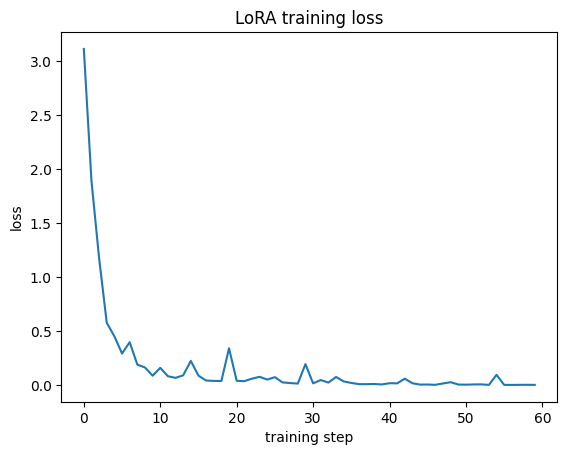

In [ ]:
def collate(batch):
    max_len = max(len(x["input_ids"]) for x in batch)
    pad = tokenizer.pad_token_id
    ids = [x["input_ids"] + [pad] * (max_len - len(x["input_ids"])) for x in batch]
    lab = [x["labels"] + [-100] * (max_len - len(x["labels"])) for x in batch]
    att = [[1] * len(x["input_ids"]) + [0] * (max_len - len(x["input_ids"])) for x in batch]
    return {"input_ids": torch.tensor(ids, device=DEVICE),
            "attention_mask": torch.tensor(att, device=DEVICE),
            "labels": torch.tensor(lab, device=DEVICE)}

assert hasattr(model, "peft_config"), "TODO 10: wrap the model with LoRA first (Cell 8)"
EPOCHS, BATCH_SIZE, LR = 3, 8, 2e-4
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR)

losses, start = [], time.time()
model.train()
for epoch in range(EPOCHS):
    random.shuffle(train_features)
    epoch_losses = []
    for i in range(0, len(train_features), BATCH_SIZE):
        batch = collate(train_features[i:i + BATCH_SIZE])
        loss = model(**batch).loss      # forward pass: loss on the answer tokens only
        loss.backward()                 # backward pass: gradients reach only the LoRA weights
        optimizer.step()                # update the LoRA weights
        optimizer.zero_grad()
        epoch_losses.append(loss.item())
    losses += epoch_losses
    print(f"epoch {epoch + 1}/{EPOCHS}  mean loss {sum(epoch_losses) / len(epoch_losses):.3f}"
          f"  ({time.time() - start:.0f}s elapsed)")

# TODO 11 (solution)
import matplotlib.pyplot as plt
plt.plot(losses)
plt.xlabel("training step"); plt.ylabel("loss"); plt.title("LoRA training loss")
plt.show()

---
# Part F · Evaluate and compare (about 6 min)

### Cell 10 · Measure the model AFTER fine-tuning (TODO 12)
**TODO 12:** create a variable named `after_minimal` that scores the fine-tuned model on the same 30 test tickets with the **minimal** prompt.
*Hint:* do it the same way you created `before_minimal` in Cell 6, but use the label `"After FT | minimal prompt"`.

The provided lines below your code then print a comparison table of all three conditions.

⏱ **This cell takes about 20–30 seconds to run** (the model writes 30 replies).

Copy the "After" row into the **Results** section.

In [ ]:
# TODO 12 (solution)
after_minimal = evaluate(model, test_rows, SYSTEM_PROMPT, "After FT | minimal prompt")



# ---- provided: compare all three conditions ----
assert "after_minimal" in globals(), "TODO 12: create after_minimal"
print(f"\n{'':30}{'format':>8}{'category':>10}{'priority':>10}")
for name, r in [("Before | minimal prompt", before_minimal),
                ("Before | detailed prompt", before_detailed),
                ("After  | minimal prompt", after_minimal)]:
    print(f"{name:30}{r['format_ok']:>8.0%}{r['category_acc']:>10.0%}"
          f"{r['priority_acc']:>10.0%}")

  TICKET: Hello, I never got the verification code for my new account, mostly asking for future reference. - Sam
  REPLY : {"category": "account_access", "priority": "medium"}

  TICKET: Hi IT team, I never got the verification code for my new account, and I'd like it fixed sometime this week.
  REPLY : {"category": "account_access", "priority": "medium"}

  TICKET: Hello, I never got the verification code for my new account, and our payroll deadline is in two hours. Thank you!
  REPLY : {"category": "account_access", "priority": "high"}

[After FT | minimal prompt] format OK 100% | category 100% | priority 60%

                                format  category  priority
Before | minimal prompt             0%        0%        0%
Before | detailed prompt          100%       70%       40%
After  | minimal prompt           100%      100%       60%


### Cell 11 · Regression check: did we break anything?
The same general question is asked twice: once with the LoRA adapter **on**, and once with it **off** (the original model). Compare the two answers.

In [ ]:
general_q = "In one sentence, what is photosynthesis?"
helper = "You are a helpful assistant."
print("Adapter ON :", preview(generate(model, general_q, helper, max_new_tokens=60), 300))
with model.disable_adapter():
    print("Adapter OFF:", preview(generate(model, general_q, helper, max_new_tokens=60), 300))

Adapter ON : Photosynthesis is the process by which plants convert light energy into chemical energy, which is then stored in glucose.
Adapter OFF: Photosynthesis is the process by which plants, algae, and some bacteria convert light energy, usually from the sun, into chemical energy stored in glucose.


### Cell 12 · Save the adapter
Saves only the LoRA adapter (not the whole model) to a folder named `triage-lora-adapter`, then prints its size and contents. Compare the size with the roughly **988 MB** model file you downloaded in Cell 2.

✅ **Checkpoint:** about **17–18 MB** (with `r = 8`) and three files: `adapter_model.safetensors`, `adapter_config.json`, and `README.md`.

**Where are the files?** In the Colab runtime's working folder, at `/content/triage-lora-adapter`. Click the **folder icon** in the left sidebar to see them. They are **temporary** and are deleted when the runtime disconnects; to keep them, right-click each file → **Download**.

**If the three files aren't there:**
- **The folder doesn't appear in the Files panel:** click the panel's refresh button. If it's still missing, rerun Cell 12.
- **Different files are listed** (such as `model.safetensors` or `config.json`) **and the folder is about 2 GB:** the model wasn't wrapped with LoRA, so the whole model was saved. Restart the session and rerun from Cell 1, making sure TODO 10 in Cell 8 is complete.
- **`FileNotFoundError`, or the folder disappeared later:** the runtime was reset, which deletes everything in it. Rerun from Cell 1.

> **Instructor note: what the three saved files are**
> - **`adapter_model.safetensors`**: the trained LoRA weights (the small A and B matrices for every targeted layer). With `r = 8` that's 4,399,104 parameters × 4 bytes (float32) ≈ **17.6 MB**, versus about 988 MB for the base model. `.safetensors` is a fast, safe file format for storing tensors.
> - **`adapter_config.json`**: the LoRA settings (`r`, `lora_alpha`, `lora_dropout`, `target_modules`, task type) and the name of the base model. PEFT reads it to rebuild the same adapter structure and attach it to the correct base model.
> - **`README.md`**: an auto-generated model card template (base model, library, and placeholder sections for intended use, training data, and limitations) to fill in before sharing the adapter.
>
> **Reusing the adapter later:** load the base model `Qwen/Qwen2.5-0.5B-Instruct`, then attach the adapter with `PeftModel.from_pretrained(base_model, "triage-lora-adapter")` (`from peft import PeftModel`).

In [ ]:
import os
model.save_pretrained("triage-lora-adapter")
size_mb = sum(os.path.getsize(os.path.join("triage-lora-adapter", f))
              for f in os.listdir("triage-lora-adapter")) / 1e6
print(f"Adapter folder: {size_mb:.1f} MB")
print(os.listdir("triage-lora-adapter"))

---
# Part G · Reflect (2+ min)
Double-click this cell and answer each question below its prompt.

1. Which metric changed the most after fine-tuning: format, category, or priority? Why do you think that is?
   *Answer key:* Compared with the **minimal** prompt, **format** changes most (prose → valid JSON), because fine-tuning teaches the exact output shape. Compared with the **detailed** prompt, which already produced valid JSON, the gain (if any) shows up in **priority**, where the prompted model mostly defaulted to "high". This illustrates that fine-tuning mainly teaches behavior and format.

2. Your cleaning function did not catch the 3 mislabeled rows. How would you find them in a real project?
   *Answer key:* Human review of a sample; clear labeling guidelines; two people labeling the same items and checking agreement; flagging rows where a trained model confidently disagrees with the label; checking keyword-label mismatches (e.g., "printer" labeled as Wi-Fi).

3. What happened in the regression check (Cell 11)? Name the phenomenon and one way to reduce it.
   *Answer key:* With the adapter on, the model may answer a general question in the ticket-JSON format or give a worse answer than with it off. That's over-specialization, a form of **catastrophic forgetting**. Mitigations: fewer epochs, mixing in general instruction data, a lower rank or learning rate, a regression test set, or enabling the adapter only for triage requests.

---
## Deliverable
Submit your `.ipynb` (**File → Download → Download .ipynb**) with **all outputs visible**, the completed **Results** section (dataset check and model results), and your **reflection answers**, on Blackboard by the Thursday lab deadline.


## If something goes wrong
| Symptom | Fix |
|---|---|
| `GPU available: False` | Runtime → Change runtime type → T4 GPU → Save, then rerun Cell 1 |
| `TypeError` mentioning `dtype` in Cell 2 | Change `dtype=` to `torch_dtype=`, or run `!pip install -q -U transformers peft accelerate` and restart |
| Error after installing | Runtime → Restart session, then rerun from Cell 1 |
| Cell 4 doesn't print 153 | Check that your function handles all three rules (TODO 2–4) and returns the cleaned list |
| `AssertionError` in Cell 4, 5, 6, 7, 9, or 10 | The message names the unfinished TODO |
| PEFT error or odd results after rerunning Cell 8 | LoRA was applied twice: restart and rerun from Cell 1 |
| CUDA out of memory | Restart; set `BATCH_SIZE = 4` in Cell 9 |
| After-FT scores barely changed | Check that the loss decreased in Cell 9, then check TODO 8 |
| `ImportError` mentioning `torchao` in Cell 8 | Cell 1 removes torchao automatically. If you still see this, run `!pip uninstall -y torchao` in a new cell, then **Runtime → Restart session** and rerun from Cell 1 |
| Cell 12 doesn't list the three adapter files | See "If the three files aren't there" in the Cell 12 instructions |
| `SyntaxError` in Cell 8 | Enter whole-number values for `r` and `lora_alpha` on the marked lines (TODO 9) |